# **1) EDA & Cleaning Script**

**Purpose:** Initial data preparation for the Art Institute of Chicago paintings dataset. Includes data cleaning, null value handling, style combining, remapping, recategorization, and exploratory data analysis with bar charts and co-occurrence heatmaps. Output is a cleaned paintings CSV with new style labels.

**Language:** Python 3  
**IDE:** Google Colab / Jupyter Notebook (`.ipynb`)  
**Input:** `aic_paintings_movements_links (1).csv`  
**Output:** `cleaned_aic_paintings_colab.csv`  
**Packages:** pandas, numpy, matplotlib, seaborn  
**Order:** Run all cells from top to bottom before model training.

**Important:** Source labels mix art movements, regional traditions, and historical periods. The grouped labels are modeling-oriented categories, not new verified art-historical attributions. Century-only labels remain explicitly marked as unspecified styles.

In [ ]:
#importing packages
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
# Mounting Google Drive (only needed when running in Google Colab with a file in Drive)
# from google.colab import drive
# drive.mount('/content/drive')

In [ ]:
#Reading in the CSV and creating initial Data Frame
# In Colab, upload your CSV to the Files sidebar, or replace path with its Google Drive path.
path = 'aic_paintings_movements_links (1).csv'
paintings_df = pd.read_csv(path)
print('Original dataset shape:', paintings_df.shape)

#Cleaning and reducing data frame to the correct columns
columns = ['artwork_id', 'title', 'artist', 'artist_id', 'date_display',
           'date_start', 'date_end', 'place_of_origin', 'medium', 'movement',
           'all_styles', 'image_id', 'image_url', 'artwork_page', 'local_path']
paintings_df = paintings_df[columns].copy()

#Handling missing values: retain paintings with missing artists / mediums,
# since these are valid historical artworks and can still be classified.
print('Missing values before cleaning:')
print(paintings_df.isna().sum())
paintings_df = paintings_df.dropna(subset=['artwork_id', 'title'])
paintings_df = paintings_df.drop_duplicates(subset=['artwork_id']).copy()
for column in ['title', 'artist', 'place_of_origin', 'medium', 'movement', 'all_styles']:
    paintings_df[column] = paintings_df[column].astype('string').str.strip()
paintings_df['artist'] = paintings_df['artist'].fillna('Unknown Artist')
paintings_df['medium'] = paintings_df['medium'].fillna('Unknown Medium')
paintings_df['place_of_origin'] = paintings_df['place_of_origin'].fillna('Unknown Origin')
paintings_df['movement'] = paintings_df['movement'].fillna('')
paintings_df['all_styles'] = paintings_df['all_styles'].fillna('')
# Unknown years and artist IDs remain null; we do not invent numbers.

#Separating the listed style labels out (the source uses semicolons, not commas)
paintings_df['style_list'] = paintings_df['all_styles'].apply(
    lambda x: [g.strip() for g in str(x).split(';') if g.strip()]
)
# Include the movement column as well when it is missing from all_styles.
paintings_df['style_list'] = paintings_df.apply(
    lambda row: list(dict.fromkeys(([row['movement']] if row['movement'] else []) + row['style_list'])),
    axis=1
)
paintings_df['num_styles'] = paintings_df['style_list'].apply(len)
display(paintings_df.head(10))

Original dataset shape: (1586, 15)
Missing values before cleaning:
artwork_id           0
title                0
artist             114
artist_id          114
date_display         0
date_start           1
date_end             1
place_of_origin      0
medium              68
movement             0
all_styles           0
image_id             0
image_url            0
artwork_page         0
local_path           0
dtype: int64


,artwork_id,title,artist,artist_id,date_display,date_start,date_end,place_of_origin,medium,movement,all_styles,image_id,image_url,artwork_page,local_path,style_list,num_styles
0,20684,Paris Street; Rainy Day,Gustave Caillebotte,3829.0,1877,1877.0,1877.0,Paris,Oil on canvas,Impressionism,Impressionism; 19th century,f8fd76e9-c396-5678-36ed-6a348c904d27,https://www.artic.edu/iiif/2/f8fd76e9-c396-567...,https://www.artic.edu/artworks/20684,images/Impressionism/20684.jpg,"[Impressionism, 19th century]",2
1,64818,Stacks of Wheat (End of Summer),Claude Monet,35809.0,1890–91,1890.0,1891.0,France,Oil on canvas,Impressionism,Impressionism; nineteenth century; 19th century,a38e2828-ec6f-ece1-a30f-70243449197b,https://www.artic.edu/iiif/2/a38e2828-ec6f-ece...,https://www.artic.edu/artworks/64818,images/Impressionism/64818.jpg,"[Impressionism, nineteenth century, 19th century]",3
2,16568,Water Lilies,Claude Monet,35809.0,1906,1906.0,1906.0,France,Oil on canvas,Impressionism,Impressionism; 20th Century,3c27b499-af56-f0d5-93b5-a7f2f1ad5813,https://www.artic.edu/iiif/2/3c27b499-af56-f0d...,https://www.artic.edu/artworks/16568,images/Impressionism/16568.jpg,"[Impressionism, 20th Century]",2
3,14655,Two Sisters (On the Terrace),Pierre-Auguste Renoir,36351.0,1881,1881.0,1881.0,France,Oil on canvas,Impressionism,Impressionism; nineteenth century; 19th century,3a608f55-d76e-fa96-d0b1-0789fbc48f1e,https://www.artic.edu/iiif/2/3a608f55-d76e-fa9...,https://www.artic.edu/artworks/14655,images/Impressionism/14655.jpg,"[Impressionism, nineteenth century, 19th century]",3
4,111442,The Child's Bath,Mary Cassatt,33890.0,1893,1893.0,1893.0,France,Oil on canvas,Impressionism,Impressionism; Modernism,3b885ae0-4d46-5fe4-d70a-00474827f02c,https://www.artic.edu/iiif/2/3b885ae0-4d46-5fe...,https://www.artic.edu/artworks/111442,images/Impressionism/111442.jpg,"[Impressionism, Modernism]",2
5,16571,"Arrival of the Normandy Train, Gare Saint-Lazare",Claude Monet,35809.0,1877,1877.0,1877.0,France,Oil on canvas,Impressionism,Impressionism; nineteenth century; 19th century,0f1cc0e0-e42e-be16-3f71-2022da38cb93,https://www.artic.edu/iiif/2/0f1cc0e0-e42e-be1...,https://www.artic.edu/artworks/16571,images/Impressionism/16571.jpg,"[Impressionism, nineteenth century, 19th century]",3
6,11723,Woman at Her Toilette,Berthe Morisot,35834.0,1875–80,1870.0,1880.0,France,Oil on canvas,Impressionism,Impressionism; nineteenth century; 19th century,78c80988-6524-cec7-c661-a4c0a706d06f,https://www.artic.edu/iiif/2/78c80988-6524-cec...,https://www.artic.edu/artworks/11723,images/Impressionism/11723.jpg,"[Impressionism, nineteenth century, 19th century]",3
7,14598,The Beach at Sainte-Adresse,Claude Monet,35809.0,1867,1867.0,1867.0,France,Oil on canvas,Impressionism,Impressionism; nineteenth century; 19th century,95be2572-b53d-8e7b-abc9-10eb48d4fa5d,https://www.artic.edu/iiif/2/95be2572-b53d-8e7...,https://www.artic.edu/artworks/14598,images/Impressionism/14598.jpg,"[Impressionism, nineteenth century, 19th century]",3
8,25865,The Herring Net,Winslow Homer,34988.0,1885,1885.0,1885.0,Prouts Neck,Oil on canvas,Impressionism,Impressionism; Realism; Modernism,5dca7347-c6dc-24dd-d073-d705b9cdc575,https://www.artic.edu/iiif/2/5dca7347-c6dc-24d...,https://www.artic.edu/artworks/25865,images/Impressionism/25865.jpg,"[Impressionism, Realism, Modernism]",3
9,69780,"The Fountain, Villa Torlonia, Frascati, Italy",John Singer Sargent,36540.0,1907,1907.0,1907.0,Frascati,Oil on canvas,Impressionism,Impressionism; Modernism,3f9aa9db-61e1-7060-fdb0-bfd7e41ddd08,https://www.artic.edu/iiif/2/3f9aa9db-61e1-706...,https://www.artic.edu/artworks/69780,images/Impressionism/69780.jpg,"[Impressionism, Modernism]",2


In [ ]:
#Listing all the unique styles (to identify broad time periods / traditions to recategorize)
#Styles are in a list: every element of each list is counted.
all_styles = [g for sublist in paintings_df['style_list'] for g in sublist]
style_counts = pd.Series(all_styles).value_counts()
unique_styles = style_counts.index.tolist()
print('Number of unique styles:', len(unique_styles))
print('Unique styles:', unique_styles)

Number of unique styles: 64
Unique styles: ['19th century', 'nineteenth century', '18th Century', '17th Century', 'Impressionism', 'Chinese (culture or style)', '16th Century', '15th century', 'Japanese (culture or style)', 'South Asian', 'sixteenth century', 'Renaissance', 'Realism', 'Post-Impressionism', 'Modernism', 'Baroque', 'Folk Art', 'Barbizon School', '20th Century', '14th century', 'Neoclassicism', 'romantic', 'medieval', 'Mannerism', 'asian', 'dutch', 'Gothic (medieval)', 'Indian (South Asian)', 'East Asian', 'Ashcan School', 'france', 'Japanism', 'Cubism', 'edo (japanese period)', 'empire', 'northern renaissance', 'Naturalism', 'orientalizing', 'Rococo', 'mughal', 'hungarian', 'Symbolism', 'nabis', 'nocturnal', 'Flemish', 'american colonial', 'genre painting', 'colonial', 'Pre-Raphaelite', 'austrian', 'english', '21st Century', 'british', 'classicism', '"bizarre" style', 'warfare', 'Arts of the Americas', 'momoyama', 'rajasthani', 'mewar', 'rajput', 'yüan', 'ming', 'liao']


In [ ]:
#display all style_counts of each unique style
pd.set_option('display.max_rows', None)
display(style_counts)

,count
19th century,512
nineteenth century,394
18th Century,282
17th Century,204
Impressionism,153
Chinese (culture or style),142
16th Century,124
15th century,78
Japanese (culture or style),76
South Asian,74


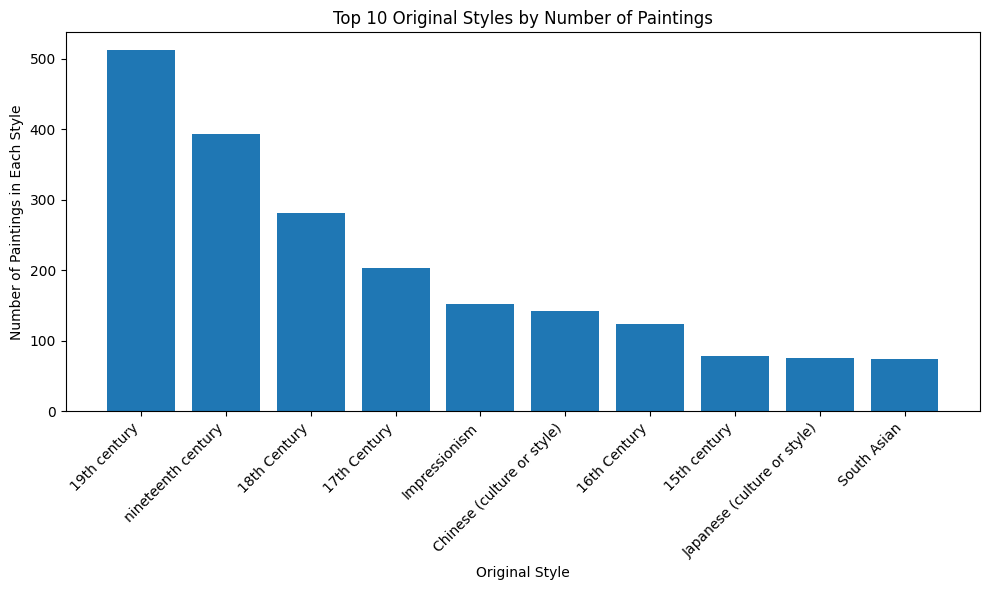

In [ ]:
#Limitation: many labels are broad centuries, not distinctive art movements.
#Make a bar chart of the style occurrences before remapping.
top_10_styles = style_counts.head(10).index
plt.figure(figsize=(10, 6))
plt.bar(top_10_styles, style_counts.loc[top_10_styles])
plt.xticks(rotation=45, ha='right')
plt.xlabel('Original Style')
plt.ylabel('Number of Paintings in Each Style')
plt.title('Top 10 Original Styles by Number of Paintings')
plt.tight_layout()
plt.show()

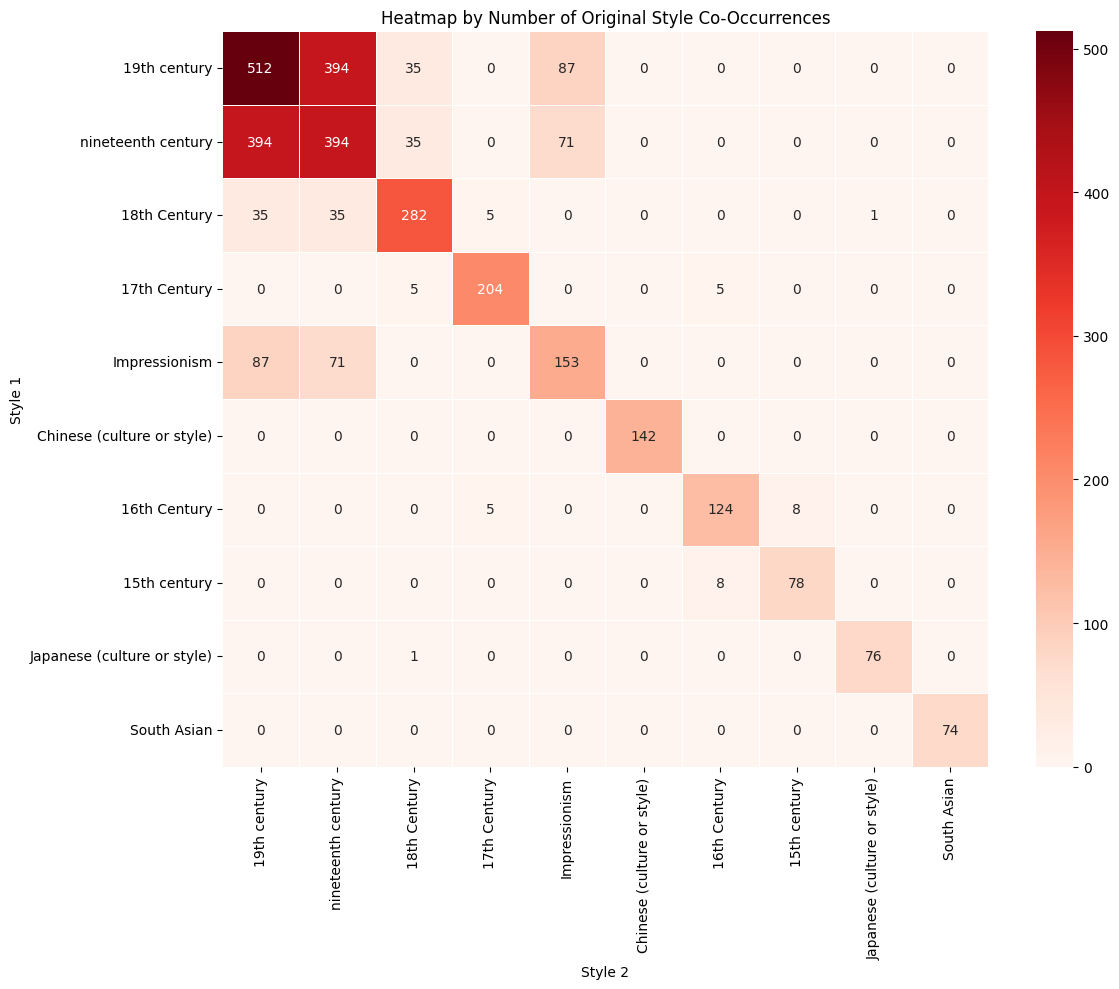

In [ ]:
#Handling for NAN values. Blank labels are excluded from the matrix.
unique_styles = sorted(set(g for sublist in paintings_df['style_list'] for g in sublist if g and g != 'nan'))

# Co-occurrence matrix (two labels associated with the same painting)
co_occurrence_matrix = pd.DataFrame(0, index=unique_styles, columns=unique_styles)
for index, row in paintings_df.iterrows():
    styles_in_painting = list(dict.fromkeys(g for g in row['style_list'] if g and g != 'nan'))
    for g1 in styles_in_painting:
        for g2 in styles_in_painting:
            co_occurrence_matrix.loc[g1, g2] += 1

filtered_matrix = co_occurrence_matrix.loc[top_10_styles, top_10_styles]
plt.figure(figsize=(12, 10))
sns.heatmap(filtered_matrix, annot=True, fmt='d', cmap='Reds', linewidths=.5)
plt.title('Heatmap by Number of Original Style Co-Occurrences')
plt.xlabel('Style 2')
plt.ylabel('Style 1')
plt.tight_layout()
plt.show()

In [ ]:
#Issue: '19th century' and 'nineteenth century' are duplicates; centuries and regions
#are not specific art movements. Small niche styles are grouped to reduce complexity.
#Below is a transparent, subjective set of target labels, modeled on the sample notebook.
#IMPORTANT: broad categories do not imply that the individual styles are historically identical.

#Listing new style categories used for remapping:
Target_Styles = [
    'Impressionism', 'Post-Impressionism', 'Realism', 'Renaissance',
    'Baroque', 'Neoclassicism', 'Modernism', 'Folk Art',
    'Chinese Art', 'Japanese Art', 'South Asian Art',
    '14th Century (Unspecified Style)', '15th Century (Unspecified Style)',
    '16th Century (Unspecified Style)', '17th Century (Unspecified Style)',
    '18th Century (Unspecified Style)', '19th Century (Unspecified Style)',
    'Unclassified'
]

#Combining old style delineations with new style categories.
#The 21 unique primary movement labels are all addressed by these rules.
Merged_Styles = [
    (['Realism'], ['Barbizon School']),
    (['Renaissance'], ['Mannerism']),
    (['Chinese Art'], ['Chinese (culture or style)']),
    (['Japanese Art'], ['Japanese (culture or style)']),
    (['South Asian Art'], ['South Asian']),
    (['14th Century (Unspecified Style)'], ['14th century']),
    (['15th Century (Unspecified Style)'], ['15th century']),
    (['16th Century (Unspecified Style)'], ['16th Century', 'sixteenth century', '16th century']),
    (['17th Century (Unspecified Style)'], ['17th Century', '17th century']),
    (['18th Century (Unspecified Style)'], ['18th Century', '18th century']),
    (['19th Century (Unspecified Style)'], ['19th century', 'nineteenth century', '19th Century']),
]

Style_Map = {}
for targets, sources in Merged_Styles:
    for src in sources:
        Style_Map.setdefault(src.casefold(), [])
        for t in targets:
            if t not in Style_Map[src.casefold()]:
                Style_Map[src.casefold()].append(t)
for g in Target_Styles:
    Style_Map.setdefault(g.casefold(), [g])

#Handling for mistakes: check every produced label is a target label.
bad = {t for ts in Style_Map.values() for t in ts} - set(Target_Styles)
assert not bad, f'Unknown target labels in rules: {bad}'

#Remapping Function (list in, deduplicated list out, same structure as the sample)
def remap_styles(styles):
    if not isinstance(styles, (list, tuple, np.ndarray)):
        return []
    out = []
    for g in styles:
        for t in Style_Map.get(str(g).strip().casefold(), []):
            if t not in out:
                out.append(t)
    return out

paintings_df['style_mapped'] = paintings_df['style_list'].apply(remap_styles)

#Track source labels that were not mapped.
orig = paintings_df['style_list'].explode().dropna().astype(str).str.strip()
dropped_counts = orig[~orig.str.casefold().isin(Style_Map.keys())].value_counts()
print('Unmapped source labels (top 25):')
print(dropped_counts.head(25))

no_label = paintings_df['style_mapped'].str.len() == 0
print(f'\nPaintings with no style after mapping: {no_label.sum()} of {len(paintings_df)} '
      f'({no_label.mean():.1%})')

mapped_counts = paintings_df['style_mapped'].explode().value_counts()
print('\nPaintings per mapped label:')
print(mapped_counts)

#Creating new data frame for model training, like cleaned_book_df in the example.
cleaned_paintings_df = pd.DataFrame({
    'artwork_id': paintings_df['artwork_id'],
    'title': paintings_df['title'],
    'artist': paintings_df['artist'],
    'movement_original': paintings_df['movement'],
    'Style': paintings_df['style_mapped'],
    'date_display': paintings_df['date_display'],
    'date_start': paintings_df['date_start'],
    'date_end': paintings_df['date_end'],
    'place_of_origin': paintings_df['place_of_origin'],
    'medium': paintings_df['medium'],
    'image_url': paintings_df['image_url'],
    'artwork_page': paintings_df['artwork_page'],
    'local_path': paintings_df['local_path']
})

#Additional cleaning for empty style columns (retain as explicit Unclassified instead
#of silently discarding the corresponding paintings).
initial_rows = len(cleaned_paintings_df)
cleaned_paintings_df['Style'] = cleaned_paintings_df['Style'].apply(
    lambda styles: styles if len(styles) > 0 else ['Unclassified']
)
print(f'Preserved {len(cleaned_paintings_df)} of {initial_rows} paintings.')
print('DataFrame after remapping (first 10 rows):')
display(cleaned_paintings_df.head(10))

Unmapped source labels (top 25):
style_list
20th Century             19
romantic                  9
medieval                  8
asian                     7
dutch                     6
Gothic (medieval)         5
Ashcan School             4
Indian (South Asian)      4
East Asian                4
Cubism                    3
france                    3
Japanism                  3
edo (japanese period)     3
mughal                    2
hungarian                 2
Naturalism                2
Rococo                    2
northern renaissance      2
orientalizing             2
empire                    2
genre painting            1
nabis                     1
nocturnal                 1
Symbolism                 1
Flemish                   1
Name: count, dtype: int64

Paintings with no style after mapping: 0 of 1586 (0.0%)

Paintings per mapped label:
style_mapped
19th Century (Unspecified Style)    512
18th Century (Unspecified Style)    282
17th Century (Unspecified Style)    204
Impressioni

,artwork_id,title,artist,movement_original,Style,date_display,date_start,date_end,place_of_origin,medium,image_url,artwork_page,local_path
0,20684,Paris Street; Rainy Day,Gustave Caillebotte,Impressionism,"[Impressionism, 19th Century (Unspecified Style)]",1877,1877.0,1877.0,Paris,Oil on canvas,https://www.artic.edu/iiif/2/f8fd76e9-c396-567...,https://www.artic.edu/artworks/20684,images/Impressionism/20684.jpg
1,64818,Stacks of Wheat (End of Summer),Claude Monet,Impressionism,"[Impressionism, 19th Century (Unspecified Style)]",1890–91,1890.0,1891.0,France,Oil on canvas,https://www.artic.edu/iiif/2/a38e2828-ec6f-ece...,https://www.artic.edu/artworks/64818,images/Impressionism/64818.jpg
2,16568,Water Lilies,Claude Monet,Impressionism,[Impressionism],1906,1906.0,1906.0,France,Oil on canvas,https://www.artic.edu/iiif/2/3c27b499-af56-f0d...,https://www.artic.edu/artworks/16568,images/Impressionism/16568.jpg
3,14655,Two Sisters (On the Terrace),Pierre-Auguste Renoir,Impressionism,"[Impressionism, 19th Century (Unspecified Style)]",1881,1881.0,1881.0,France,Oil on canvas,https://www.artic.edu/iiif/2/3a608f55-d76e-fa9...,https://www.artic.edu/artworks/14655,images/Impressionism/14655.jpg
4,111442,The Child's Bath,Mary Cassatt,Impressionism,"[Impressionism, Modernism]",1893,1893.0,1893.0,France,Oil on canvas,https://www.artic.edu/iiif/2/3b885ae0-4d46-5fe...,https://www.artic.edu/artworks/111442,images/Impressionism/111442.jpg
5,16571,"Arrival of the Normandy Train, Gare Saint-Lazare",Claude Monet,Impressionism,"[Impressionism, 19th Century (Unspecified Style)]",1877,1877.0,1877.0,France,Oil on canvas,https://www.artic.edu/iiif/2/0f1cc0e0-e42e-be1...,https://www.artic.edu/artworks/16571,images/Impressionism/16571.jpg
6,11723,Woman at Her Toilette,Berthe Morisot,Impressionism,"[Impressionism, 19th Century (Unspecified Style)]",1875–80,1870.0,1880.0,France,Oil on canvas,https://www.artic.edu/iiif/2/78c80988-6524-cec...,https://www.artic.edu/artworks/11723,images/Impressionism/11723.jpg
7,14598,The Beach at Sainte-Adresse,Claude Monet,Impressionism,"[Impressionism, 19th Century (Unspecified Style)]",1867,1867.0,1867.0,France,Oil on canvas,https://www.artic.edu/iiif/2/95be2572-b53d-8e7...,https://www.artic.edu/artworks/14598,images/Impressionism/14598.jpg
8,25865,The Herring Net,Winslow Homer,Impressionism,"[Impressionism, Realism, Modernism]",1885,1885.0,1885.0,Prouts Neck,Oil on canvas,https://www.artic.edu/iiif/2/5dca7347-c6dc-24d...,https://www.artic.edu/artworks/25865,images/Impressionism/25865.jpg
9,69780,"The Fountain, Villa Torlonia, Frascati, Italy",John Singer Sargent,Impressionism,"[Impressionism, Modernism]",1907,1907.0,1907.0,Frascati,Oil on canvas,https://www.artic.edu/iiif/2/3f9aa9db-61e1-706...,https://www.artic.edu/artworks/69780,images/Impressionism/69780.jpg


Number of unique styles: 17
Unique styles: ['14th Century (Unspecified Style)', '15th Century (Unspecified Style)', '16th Century (Unspecified Style)', '17th Century (Unspecified Style)', '18th Century (Unspecified Style)', '19th Century (Unspecified Style)', 'Baroque', 'Chinese Art', 'Folk Art', 'Impressionism', 'Japanese Art', 'Modernism', 'Neoclassicism', 'Post-Impressionism', 'Realism', 'Renaissance', 'South Asian Art']


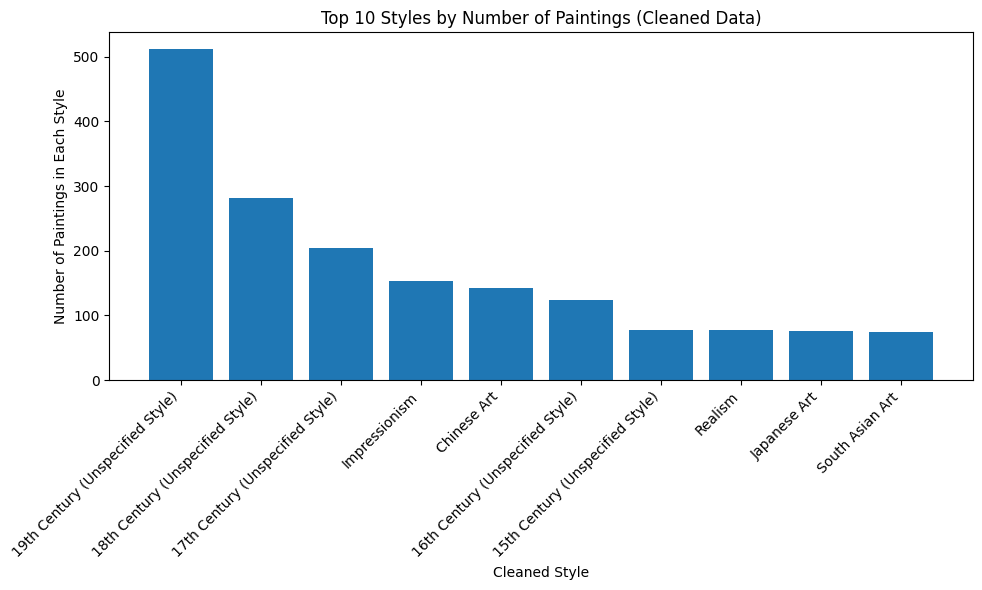

In [ ]:
#Displaying data dictionary of new reorganized styles
unique_new_styles = sorted(set(g for sublist in cleaned_paintings_df['Style'] for g in sublist))
style_counts_new = pd.Series([g for sublist in cleaned_paintings_df['Style'] for g in sublist]).value_counts()
top_10_new_styles = style_counts_new.head(10).index
print('Number of unique styles:', len(unique_new_styles))
print('Unique styles:', unique_new_styles)

#Bar chart showing the most frequent cleaned style labels.
plt.figure(figsize=(10, 6))
plt.bar(top_10_new_styles, style_counts_new.loc[top_10_new_styles])
plt.xticks(rotation=45, ha='right')
plt.xlabel('Cleaned Style')
plt.ylabel('Number of Paintings in Each Style')
plt.title('Top 10 Styles by Number of Paintings (Cleaned Data)')
plt.tight_layout()
plt.show()

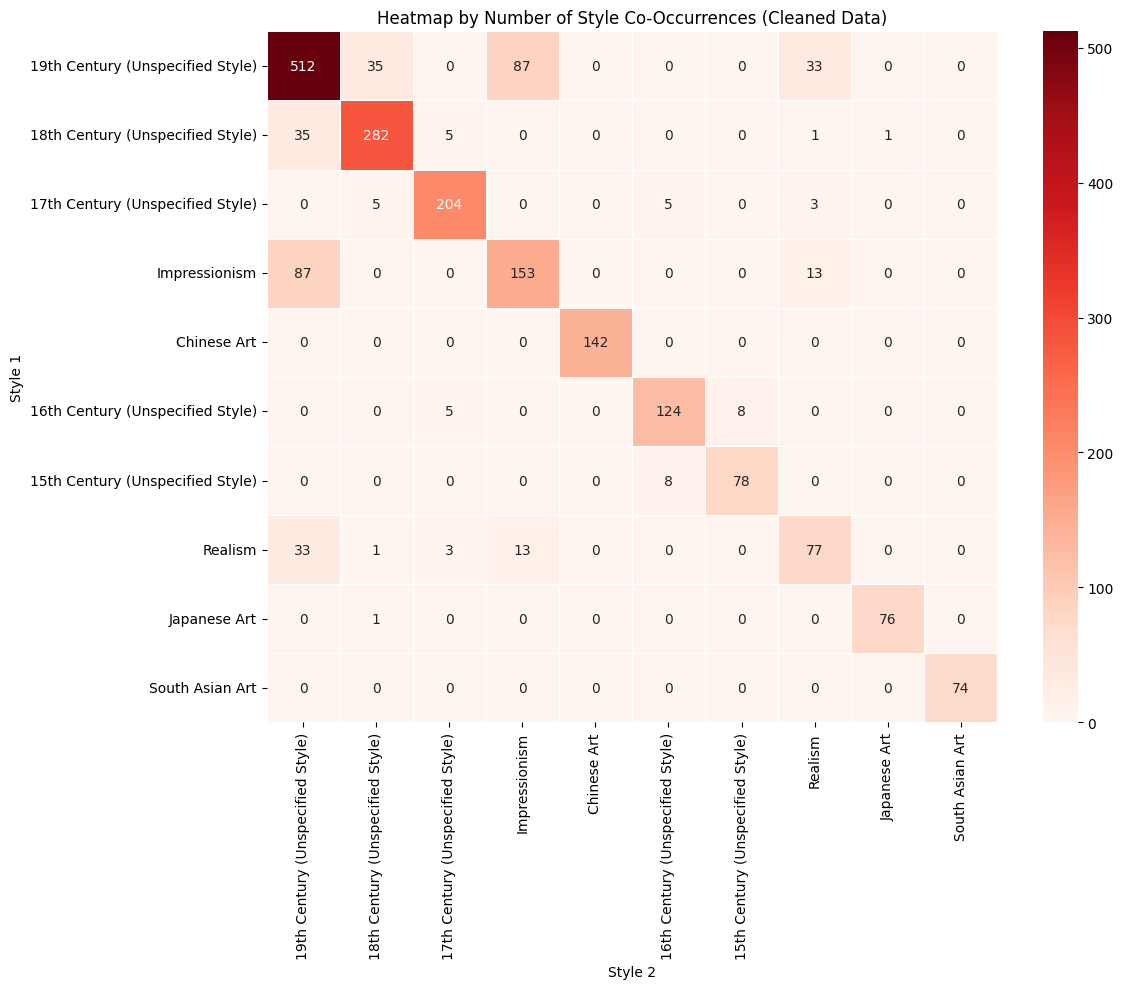

In [ ]:
#Displaying a New Heatmap of the cleaned DF
#Creating new co-occurrence matrix
unique_new_styles = sorted(set(g for sublist in cleaned_paintings_df['Style'] for g in sublist))
new_co_occurrence_matrix = pd.DataFrame(0, index=unique_new_styles, columns=unique_new_styles)
for index, row in cleaned_paintings_df.iterrows():
    styles_in_painting = list(dict.fromkeys(row['Style']))
    for g1 in styles_in_painting:
        for g2 in styles_in_painting:
            new_co_occurrence_matrix.loc[g1, g2] += 1

filtered_matrix_cleaned = new_co_occurrence_matrix.loc[top_10_new_styles, top_10_new_styles]
plt.figure(figsize=(12, 10))
sns.heatmap(filtered_matrix_cleaned, annot=True, fmt='d', cmap='Reds', linewidths=.5)
plt.title('Heatmap by Number of Style Co-Occurrences (Cleaned Data)')
plt.xlabel('Style 2')
plt.ylabel('Style 1')
plt.tight_layout()
plt.show()

In [ ]:
# Downloading new data for modeling, like the original example.
# The Style column contains comma-separated labels for compatibility with CSV.
cleaned_paintings_df.assign(Style=cleaned_paintings_df['Style'].str.join(', ')) \
    .to_csv('cleaned_aic_paintings_colab.csv', index=False)

#Also export the distribution of cleaned labels for easy review.
style_counts_new.rename_axis('Style').reset_index(name='painting_count') \
    .to_csv('cleaned_aic_style_counts_colab.csv', index=False)

print('Saved cleaned_aic_paintings_colab.csv')
print('Saved cleaned_aic_style_counts_colab.csv')
# End of the initial data cleaning and EDA notebook.

Saved cleaned_aic_paintings_colab.csv
Saved cleaned_aic_style_counts_colab.csv
